<a href="https://colab.research.google.com/github/jindalritik-error/RJ-Stock-Market-Analysis-Prediction-using-AI-Public/blob/main/Stock_Market_Analysis_%26_Prediction_using_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [68]:
!pip install yfinance -q

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

print("All libraries imported successfully!")

All libraries imported successfully!


In [70]:
# Download 5 years of historical stock data

stock = yf.Ticker("RELIANCE.NS")

df = stock.history(
    period="5y",
    interval="1d",
    auto_adjust=True
)

# Convert date index into a column
df.reset_index(inplace=True)

print("Dataset downloaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

df.head()

Dataset downloaded successfully!
Total Rows: 1236
Total Columns: 8


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2021-11-15 00:00:00+05:30,1177.586582,1178.583082,1163.999068,1167.531860,4803269,0.0,0.0
1,2021-11-16 00:00:00+05:30,1164.927503,1166.263636,1130.030266,1140.402100,11337581,0.0,0.0
2,2021-11-17 00:00:00+05:30,1131.819203,1131.819203,1114.630971,1115.989746,10202029,0.0,0.0
3,2021-11-18 00:00:00+05:30,1114.178225,1127.312896,1109.671696,1120.202026,8505625,0.0,0.0
4,2021-11-22 00:00:00+05:30,1103.353215,1109.195876,1064.809860,1070.584595,24124307,0.0,0.0


In [71]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(1236, 8)

Column Names:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1236 entries, 0 to 1235
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype                       
---  ------        --------------  -----                       
 0   Date          1236 non-null   datetime64[ns, Asia/Kolkata]
 1   Open          1236 non-null   float64                     
 2   High          1236 non-null   float64                     
 3   Low           1236 non-null   float64                     
 4   Close         1236 non-null   float64                     
 5   Volume        1236 non-null   int64                       
 6   Dividends     1236 non-null   float64                     
 7   Stock Splits  1236 non-null   float64                     
dtypes: datetime64[ns, Asia/Kolkata](1), float64(6), int64(1)
memory usage: 77.4 KB

First 5 Rows:


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2021-11-15 00:00:00+05:30,1177.586582,1178.583082,1163.999068,1167.531860,4803269,0.0,0.0
1,2021-11-16 00:00:00+05:30,1164.927503,1166.263636,1130.030266,1140.402100,11337581,0.0,0.0
2,2021-11-17 00:00:00+05:30,1131.819203,1131.819203,1114.630971,1115.989746,10202029,0.0,0.0
3,2021-11-18 00:00:00+05:30,1114.178225,1127.312896,1109.671696,1120.202026,8505625,0.0,0.0
4,2021-11-22 00:00:00+05:30,1103.353215,1109.195876,1064.809860,1070.584595,24124307,0.0,0.0



Missing Values:
Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64


In [72]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Remove missing values
df.dropna(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

print("\nDataset cleaned successfully!")
print("Total records:", len(df))

Duplicate rows: 0

Missing values:
Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

Dataset cleaned successfully!
Total records: 1236


In [73]:
# Basic statistics of stock data
df.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,1236.000000,1236.000000,1236.000000,1236.000000,1.236000e+03,1236.000000,1236.000000
mean,1276.175737,1287.579236,1264.538337,1275.697040,1.344830e+07,0.020227,0.001618
std,142.351090,142.985509,141.801515,142.350943,7.141913e+06,0.320670,0.056888
min,1001.627963,1008.758398,987.361062,1000.238464,0.000000e+00,0.000000,0.000000
25%,1158.386987,1168.221204,1148.522906,1158.547546,8.859550e+06,0.000000,0.000000
50%,1257.917322,1271.346079,1245.663039,1258.760437,1.185572e+07,0.000000,0.000000
75%,1403.029778,1414.466194,1388.760392,1401.814575,1.625094e+07,0.000000,0.000000
max,1585.668486,1604.382010,1570.936597,1584.971802,8.812112e+07,6.000000,2.000000


In [74]:
print("First closing price:", df['Close'].iloc[0])
print("Latest closing price:", df['Close'].iloc[-1])

print("Highest price:", df['High'].max())
print("Lowest price:", df['Low'].min())

First closing price: 1167.5318603515625
Latest closing price: 1339.699951171875
Highest price: 1604.3820104615531
Lowest price: 987.3610616449254


In [75]:
df['MA_50'] = df['Close'].rolling(window=50).mean()

df['MA_100'] = df['Close'].rolling(window=100).mean()

df['MA_200'] = df['Close'].rolling(window=200).mean()

df[['Date', 'Close', 'MA_50', 'MA_100', 'MA_200']].tail()

,Date,Close,MA_50,MA_100,MA_200
1231,2026-11-06 00:00:00+05:30,1320.000000,1235.590000,1271.109001,1322.414041
1232,2026-11-09 00:00:00+05:30,1324.400024,1236.118000,1271.065001,1321.775610
1233,2026-11-11 00:00:00+05:30,1335.400024,1237.182002,1271.092002,1321.196658
1234,2026-11-12 00:00:00+05:30,1339.699951,1238.236001,1271.208002,1320.859688
1235,2026-11-13 00:00:00+05:30,1339.699951,1239.490000,1271.510001,1320.620266


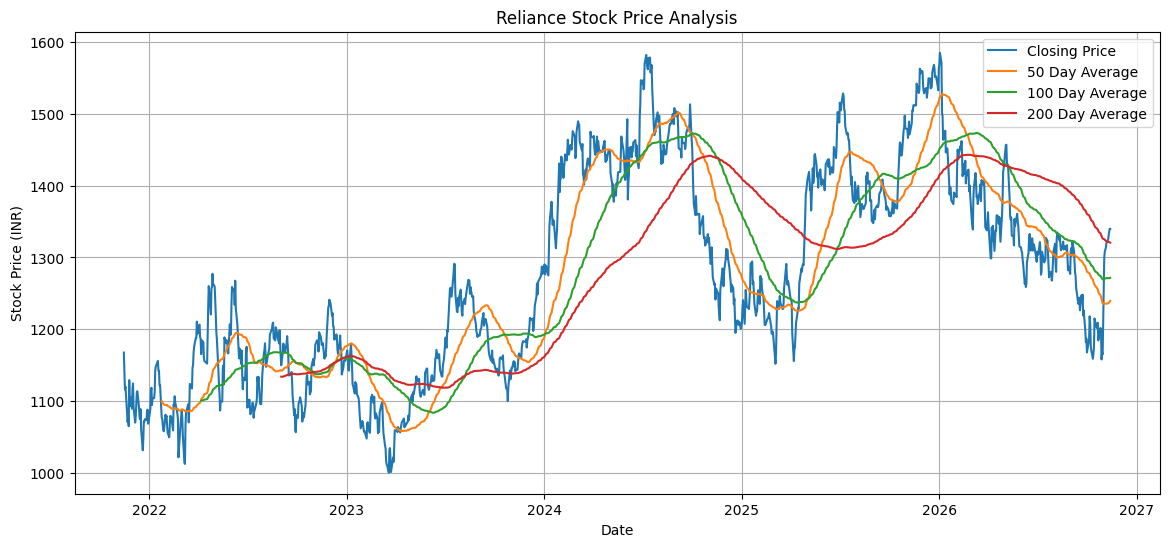

In [76]:
plt.figure(figsize=(14, 6))

plt.plot(df['Date'], df['Close'], label='Closing Price')
plt.plot(df['Date'], df['MA_50'], label='50 Day Average')
plt.plot(df['Date'], df['MA_100'], label='100 Day Average')
plt.plot(df['Date'], df['MA_200'], label='200 Day Average')

plt.title('Reliance Stock Price Analysis')
plt.xlabel('Date')
plt.ylabel('Stock Price (INR)')

plt.legend()
plt.grid()
plt.show()

In [77]:
df['Daily_Change'] = df['Close'] - df['Open']

df['Change_Percentage'] = (
    (df['Close'] - df['Open']) / df['Open']
) * 100

df[['Date', 'Open', 'Close', 'Daily_Change', 'Change_Percentage']].tail()

,Date,Open,Close,Daily_Change,Change_Percentage
1231,2026-11-06 00:00:00+05:30,1295.000000,1320.000000,25.000000,1.930502
1232,2026-11-09 00:00:00+05:30,1317.000000,1324.400024,7.400024,0.561885
1233,2026-11-11 00:00:00+05:30,1333.500000,1335.400024,1.900024,0.142484
1234,2026-11-12 00:00:00+05:30,1335.400024,1339.699951,4.299927,0.321995
1235,2026-11-13 00:00:00+05:30,1336.599976,1339.699951,3.099976,0.231930


In [78]:
df['Previous_Close'] = df['Close'].shift(1)

df['Price_Difference'] = df['Close'] - df['Previous_Close']

df[['Date', 'Close', 'Previous_Close', 'Price_Difference']].tail()

,Date,Close,Previous_Close,Price_Difference
1231,2026-11-06 00:00:00+05:30,1320.000000,1313.400024,6.599976
1232,2026-11-09 00:00:00+05:30,1324.400024,1320.000000,4.400024
1233,2026-11-11 00:00:00+05:30,1335.400024,1324.400024,11.000000
1234,2026-11-12 00:00:00+05:30,1339.699951,1335.400024,4.299927
1235,2026-11-13 00:00:00+05:30,1339.699951,1339.699951,0.000000


In [79]:
print("Average Volume:", df['Volume'].mean())

print("Maximum Volume:", df['Volume'].max())

print("Minimum Volume:", df['Volume'].min())

Average Volume: 13448296.264563106
Maximum Volume: 88121121
Minimum Volume: 0


In [80]:
print(df.columns.tolist())

['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits', 'MA_50', 'MA_100', 'MA_200', 'Daily_Change', 'Change_Percentage', 'Previous_Close', 'Price_Difference']


In [81]:
df['Daily_Return'] = (df['Close'].pct_change()) * 100

print("Daily Return column added!")
display(df[['Date', 'Close', 'Daily_Return']].tail())

Daily Return column added!


,Date,Close,Daily_Return
1231,2026-11-06 00:00:00+05:30,1320.000000,0.502511
1232,2026-11-09 00:00:00+05:30,1324.400024,0.333335
1233,2026-11-11 00:00:00+05:30,1335.400024,0.830565
1234,2026-11-12 00:00:00+05:30,1339.699951,0.321995
1235,2026-11-13 00:00:00+05:30,1339.699951,0.000000


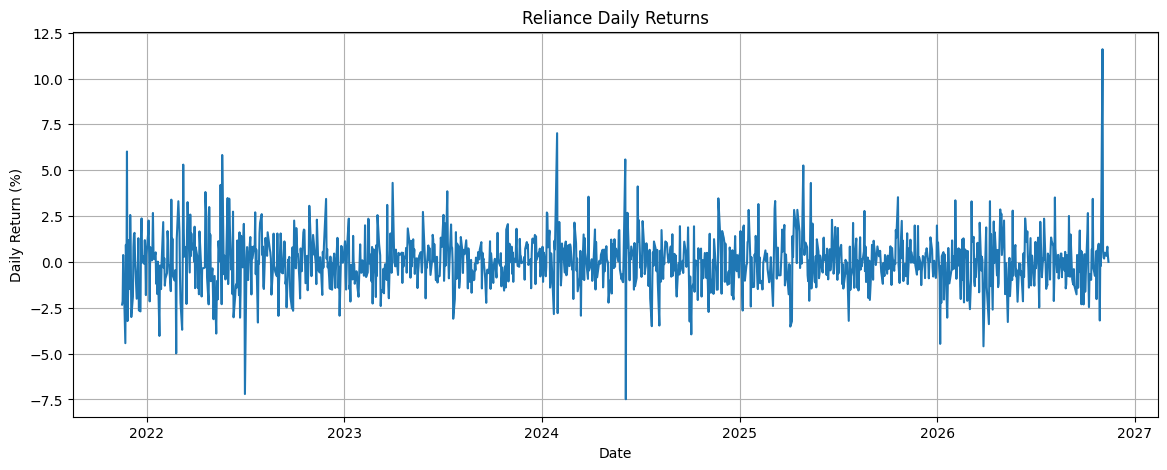

In [82]:
plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['Daily_Return'])

plt.title('Reliance Daily Returns')
plt.xlabel('Date')
plt.ylabel('Daily Return (%)')

plt.grid()
plt.show()

In [83]:
df = df.dropna().copy()

features = ['Open', 'High', 'Low', 'Close', 'Volume',
            'MA_50', 'MA_100', 'MA_200',
            'Daily_Change', 'Daily_Return']

df[features].head()

,Open,High,Low,Close,Volume,MA_50,MA_100,MA_200,Daily_Change,Daily_Return
199,1163.434681,1170.227888,1147.667157,1149.848267,12999345,1142.391130,1167.317302,1133.973966,-13.586414,-1.167786
200,1150.075446,1173.022473,1150.075446,1167.706055,11327815,1143.048628,1167.147615,1133.974837,17.630608,1.553056
201,1169.160155,1184.155211,1168.705712,1179.997437,10899618,1144.320178,1167.125526,1134.172814,10.837281,1.052609
202,1170.068949,1179.111415,1167.796974,1173.136108,7488501,1145.136548,1167.257432,1134.458546,3.067160,-0.581470
203,1176.089616,1180.519984,1168.251346,1174.794556,7057077,1146.053120,1167.448497,1134.731508,-1.295060,0.141369


In [84]:
df['Next_Close'] = df['Close'].shift(-1)

df = df.dropna().copy()

df[['Date', 'Close', 'Next_Close']].head()

,Date,Close,Next_Close
199,2022-09-02 00:00:00+05:30,1149.848267,1167.706055
200,2022-09-05 00:00:00+05:30,1167.706055,1179.997437
201,2022-09-06 00:00:00+05:30,1179.997437,1173.136108
202,2022-09-07 00:00:00+05:30,1173.136108,1174.794556
203,2022-09-08 00:00:00+05:30,1174.794556,1167.478882


In [85]:
X = df[features]

y = df['Next_Close']

print("Input data shape:", X.shape)
print("Output data shape:", y.shape)

Input data shape: (1036, 10)
Output data shape: (1036,)


In [86]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (828, 10)
Testing data: (208, 10)


In [87]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Data scaling completed!")

Data scaling completed!


In [91]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

model_lr.fit(X_train, y_train)

pred_lr = model_lr.predict(X_test)

print("Linear Regression Model Trained!")

Linear Regression Model Trained!


In [92]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(n_estimators=100, random_state=42)

model_rf.fit(X_train, y_train)

pred_rf = model_rf.predict(X_test)

print("Random Forest Model Trained!")

Random Forest Model Trained!


In [93]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr_mae = mean_absolute_error(y_test, pred_lr)
rf_mae = mean_absolute_error(y_test, pred_rf)

lr_rmse = np.sqrt(mean_squared_error(y_test, pred_lr))
rf_rmse = np.sqrt(mean_squared_error(y_test, pred_rf))

lr_r2 = r2_score(y_test, pred_lr)
rf_r2 = r2_score(y_test, pred_rf)

print("Linear Regression Results")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

print("\nRandom Forest Results")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Linear Regression Results
MAE: 14.4329601415108
RMSE: 20.344477840103632
R2 Score: 0.9237611102060211

Random Forest Results
MAE: 17.8795649601863
RMSE: 24.2601582743334
R2 Score: 0.8915896547104477


In [94]:
results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Linear Regression': pred_lr,
    'Random Forest': pred_rf
})

display(results.head(10))

,Actual Price,Linear Regression,Random Forest
0,1468.510254,1462.641093,1454.362133
1,1476.373779,1466.943166,1457.042083
2,1446.113770,1471.536283,1470.519711
3,1452.086182,1443.547668,1452.989547
4,1452.086182,1450.134615,1452.422787
5,1451.190308,1449.794869,1447.169542
6,1407.094116,1451.832519,1443.580380
7,1387.584351,1404.647433,1425.243519
8,1398.135620,1386.081852,1381.515607
9,1396.045288,1395.321484,1385.550682


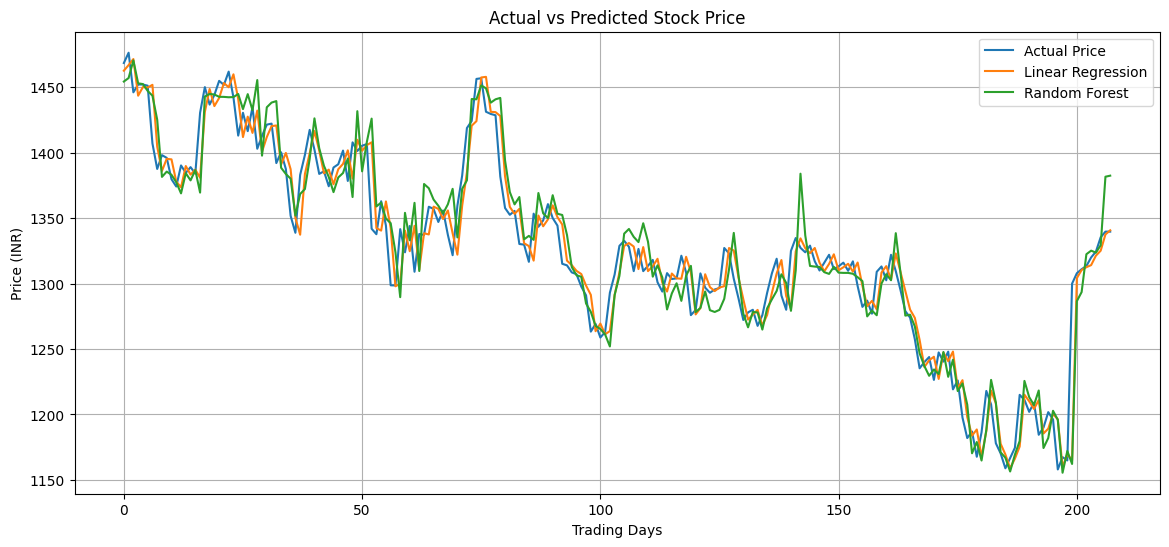

In [95]:
plt.figure(figsize=(14, 6))

plt.plot(y_test.values, label='Actual Price')
plt.plot(pred_lr, label='Linear Regression')
plt.plot(pred_rf, label='Random Forest')

plt.title('Actual vs Predicted Stock Price')
plt.xlabel('Trading Days')
plt.ylabel('Price (INR)')

plt.legend()
plt.grid()
plt.show()

In [96]:
model_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

display(model_results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,14.432960,20.344478,0.923761
1,Random Forest,17.879565,24.260158,0.891590


In [97]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler

print("TensorFlow imported successfully!")

TensorFlow imported successfully!


In [98]:
data = df[['Close']].values

scaler_lstm = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler_lstm.fit_transform(data)

print("Data prepared successfully!")
print("Total records:", len(scaled_data))

Data prepared successfully!
Total records: 1036


In [99]:
X_lstm = []
y_lstm = []

for i in range(60, len(scaled_data)):
    X_lstm.append(scaled_data[i-60:i, 0])
    y_lstm.append(scaled_data[i, 0])

X_lstm = np.array(X_lstm)
y_lstm = np.array(y_lstm)

X_lstm = X_lstm.reshape(X_lstm.shape[0], X_lstm.shape[1], 1)

print("X shape:", X_lstm.shape)
print("Y shape:", y_lstm.shape)

X shape: (976, 60, 1)
Y shape: (976,)


In [100]:
split = int(len(X_lstm) * 0.8)

X_train_lstm = X_lstm[:split]
X_test_lstm = X_lstm[split:]

y_train_lstm = y_lstm[:split]
y_test_lstm = y_lstm[split:]

print("Training data:", X_train_lstm.shape)
print("Testing data:", X_test_lstm.shape)

Training data: (780, 60, 1)
Testing data: (196, 60, 1)


In [101]:
model_lstm = Sequential([
    LSTM(50, return_sequences=True, input_shape=(60, 1)),
    Dropout(0.2),

    LSTM(50),
    Dropout(0.2),

    Dense(25),
    Dense(1)
])

model_lstm.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model_lstm.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [102]:
history = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False
)

print("LSTM Model Training Completed!")

Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - loss: 0.0174 - val_loss: 0.0106
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0128 - val_loss: 0.0069
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0089 - val_loss: 0.0051
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0078 - val_loss: 0.0051
Epoch 5/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0068 - val_loss: 0.0046
Epoch 6/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0067 - val_loss: 0.0043
Epoch 7/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0060 - val_loss: 0.0061
Epoch 8/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0050 - val_loss: 0.0039
Epoch 9/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0059 - val_loss: 0.0034
Epoch 10/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0056 - val_loss: 0.0037
Epoch 11/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0048 - val_loss: 0.0030
Epoch 12/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0

In [103]:
pred_lstm = model_lstm.predict(X_test_lstm)

pred_lstm = scaler_lstm.inverse_transform(pred_lstm)

actual_lstm = scaler_lstm.inverse_transform(
    y_test_lstm.reshape(-1, 1)
)

print("LSTM Predictions Completed!")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step
LSTM Predictions Completed!


In [104]:
lstm_mae = mean_absolute_error(actual_lstm, pred_lstm)

lstm_rmse = np.sqrt(
    mean_squared_error(actual_lstm, pred_lstm)
)

lstm_r2 = r2_score(actual_lstm, pred_lstm)

print("LSTM Results")
print("MAE:", lstm_mae)
print("RMSE:", lstm_rmse)
print("R2 Score:", lstm_r2)

LSTM Results
MAE: 26.11591323541135
RMSE: 33.09966661341256
R2 Score: 0.7836465637476397


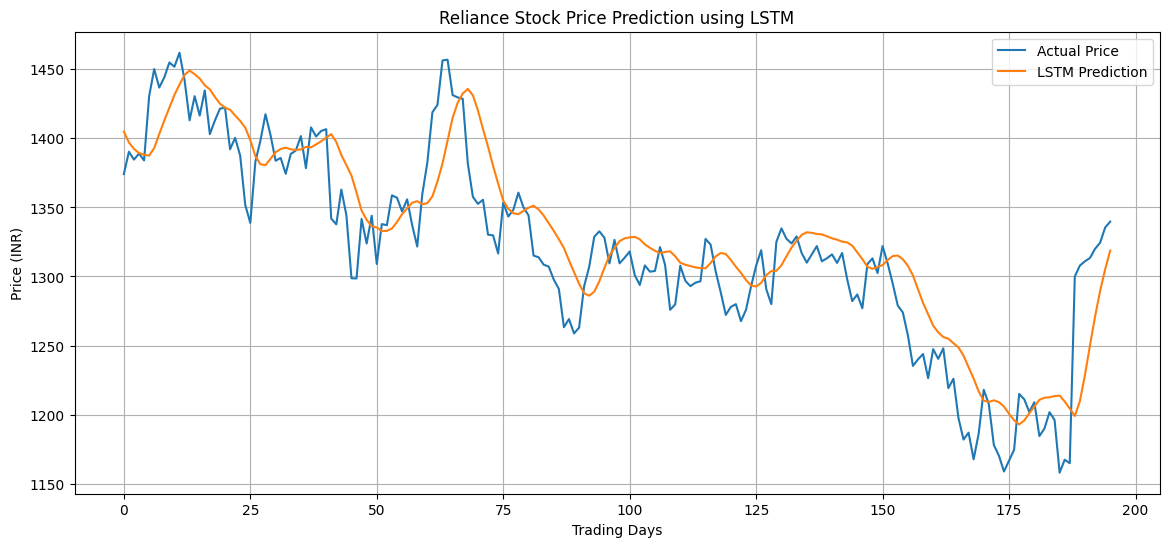

In [105]:

plt.figure(figsize=(14, 6))

plt.plot(actual_lstm, label='Actual Price')
plt.plot(pred_lstm, label='LSTM Prediction')

plt.title('Reliance Stock Price Prediction using LSTM')
plt.xlabel('Trading Days')
plt.ylabel('Price (INR)')

plt.legend()
plt.grid()
plt.show()

In [107]:
model_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'LSTM'],
    'MAE': [lr_mae, rf_mae, lstm_mae],
    'RMSE': [lr_rmse, rf_rmse, lstm_rmse],
    'R2 Score': [lr_r2, rf_r2, lstm_r2]
})

display(model_results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,14.432960,20.344478,0.923761
1,Random Forest,17.879565,24.260158,0.891590
2,LSTM,26.115913,33.099667,0.783647


In [108]:
best_model = model_results.loc[model_results['MAE'].idxmin()]

print("Best model based on MAE:")
print(best_model['Model'])

print("MAE:", best_model['MAE'])

Best model based on MAE:
Linear Regression
MAE: 14.4329601415108


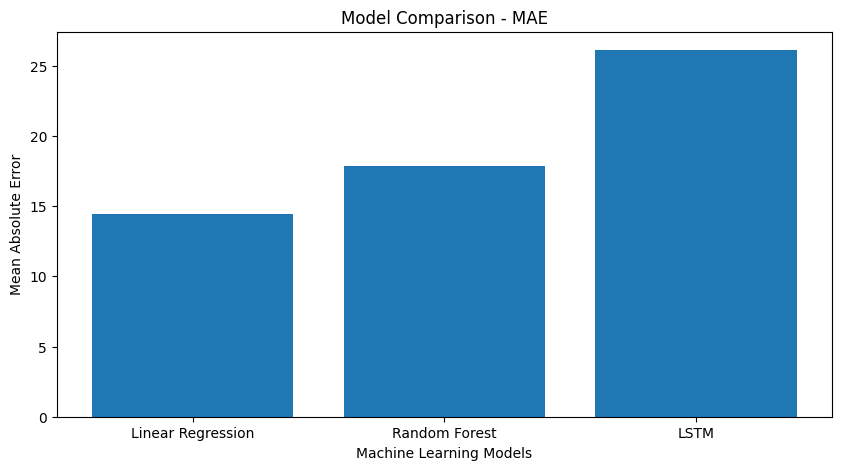

In [109]:

plt.figure(figsize=(10, 5))

plt.bar(model_results['Model'], model_results['MAE'])

plt.title('Model Comparison - MAE')
plt.xlabel('Machine Learning Models')
plt.ylabel('Mean Absolute Error')

plt.show()

In [110]:
import joblib

joblib.dump(model_lr, 'linear_regression.pkl')
joblib.dump(model_rf, 'random_forest.pkl')
joblib.dump(scaler, 'stock_scaler.pkl')

model_lstm.save('stock_lstm.keras')

print("All models saved successfully!")

All models saved successfully!
